# Introduction to PyTorch

Partly based on https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial2/Introduction_to_PyTorch.html

## What is PyTorch?

- Similar to NumPy: a library for array (tensor) operations
- ... with GPU support
- Automatic differentiation engine
- Library of neural network components
- Library of optimization tools

## Parallels between PyTorch and NumPy

Installation with `uv add torch`

If you install a current version of PyTorch, you should have version 2.9. 

In [1]:
import torch

print(torch.__version__)

2.14.1+cu130


In [2]:
import numpy as np

The equivalent to the NumPy array is the [torch Tensor](https://pytorch.org/docs/stable/tensors.html#torch.Tensor). This is a generalization of concepts u already know: 1-D tensor :: vector, 2-D tesnsor :: matrix.

In [3]:
x = torch.Tensor(2, 3, 4)
print(x)

tensor([[[2.6792e+20, 1.6020e-19, 7.1435e+31, 1.3563e-19],
         [1.1093e+27, 6.1400e+13, 8.2905e+02, 7.1831e+22],
         [4.1209e+21, 1.7609e+19, 1.9284e+31, 1.6530e+19]],

        [[1.9764e+31, 1.3563e-19, 1.1093e+27, 6.1400e+13],
         [8.2905e+02, 7.1831e+22, 4.1209e+21, 1.7609e+19],
         [1.9284e+31, 1.6530e+19, 6.7593e+34, 1.8523e+28]]])


In [4]:
data = [[1, 2], [3, 4]]

x_np = np.array(data)
x_torch = torch.Tensor(data)

print(x_np)
print(x_torch)

[[1 2]
 [3 4]]
tensor([[1., 2.],
        [3., 4.]])


Many tensor creation operations have the same names as in NumPy:

In [5]:
n_rows = 2
n_cols = 4

# Tensor filled with scalar values 0, with shape defined by arg size
zeros_torch = torch.zeros(size=(n_rows, n_cols))
print(zeros_torch)
# Array filled with zeros, given shape
zeros_np = np.zeros(shape=(n_rows, n_cols))
print(zeros_np)


ones_torch = torch.ones_like(input=zeros_torch)
ones_np = np.ones_like(a=zeros_np)
print(ones_torch)
print(ones_np)
# ...


# x = torch.zeros(3, 4) # common convention, just pass the shape arg positionally!
# x = torch.zeros((3, 4))
# x = torch.zeros(size=(3, 4))

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])
[[1. 1. 1. 1.]
 [1. 1. 1. 1.]]


Indexing works the same way.

In [6]:
x_np = np.arange(24).reshape(4, 6)
print(x_np[1:8, :])

[[ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]


In [7]:
x_np = np.arange(24).reshape(4, 6)
print(x_np)

x_torch = torch.arange(24).reshape(4, 6)
print(x_torch)

# Reminder: <start:stop:step> notation, where start is inclusive, stop exlusive
# Slicing creats a "view" instead of a copy
print(x_np[1:5:2, :])
print(x_torch[1:5:2, :])

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17],
        [18, 19, 20, 21, 22, 23]])
[[ 6  7  8  9 10 11]
 [18 19 20 21 22 23]]
tensor([[ 6,  7,  8,  9, 10, 11],
        [18, 19, 20, 21, 22, 23]])


... but there are some differences:

In [8]:
x_np = np.arange(24).reshape(4, 6)
print(x_np[0, 0], type(x_np[0, 0]))

x_torch = torch.arange(24).reshape(4, 6)
print(x_torch[0, 0], type(x_torch[0, 0]))
print(x_torch[0, 0].item(), type(x_torch[0, 0].item()))

0 <class 'numpy.int64'>
tensor(0) <class 'torch.Tensor'>
0 <class 'int'>


We can get the shape the same way.

In [9]:
print(x_np.shape)
print(x_torch.shape)

print(x_torch.size(dim=1))
print(x_torch.shape[1])

(4, 6)
torch.Size([4, 6])
6
6


You can create a tensor from an array and an array from a tensor.

In [10]:
x_np = np.arange(24).reshape(4, 6)
x_torch = torch.from_numpy(x_np)
print(x_torch)


# VS Code: Ctrl + K + C comment (line/marked code block)
# VS Code: Ctrl + K + U uncomment (line/marked code block)

x_np[0, 0] = -1000

print(x_np)
print(x_torch)

# What else has changed? (See last exercise ... call/pass by reference ...)

tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17],
        [18, 19, 20, 21, 22, 23]])
[[-1000     1     2     3     4     5]
 [    6     7     8     9    10    11]
 [   12    13    14    15    16    17]
 [   18    19    20    21    22    23]]
tensor([[-1000,     1,     2,     3,     4,     5],
        [    6,     7,     8,     9,    10,    11],
        [   12,    13,    14,    15,    16,    17],
        [   18,    19,    20,    21,    22,    23]])


In [11]:
print(x_torch.numpy())

[[-1000     1     2     3     4     5]
 [    6     7     8     9    10    11]
 [   12    13    14    15    16    17]
 [   18    19    20    21    22    23]]


Operations work just like NumPy:

In [12]:
x = torch.ones((4, 4))

print(x @ x)  # matrix multiplication
print(x + x)  # matrix addition

tensor([[4., 4., 4., 4.],
        [4., 4., 4., 4.],
        [4., 4., 4., 4.],
        [4., 4., 4., 4.]])
tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])


Some additional in-place operations that save memory. Marked with `_` at the end of the operation.

In [13]:
x = torch.ones((4, 4))

# x + x creates a new tensor, x will remain as is
_ = x.add(x)
print(x)

x.add_(x)  # in place, x will be modified
print(x)

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])


## GPU support

A Graphics Processing Unit (GPU) can be thought of as a processor with _many_ cores (think thousands), which however are limited in their instruction set.
[Kevin Krewell, 2009](https://blogs.nvidia.com/blog/2009/12/16/whats-the-difference-between-a-cpu-and-a-gpu/) gives the following comparison:
| CPU | GPU |
| -------- | -------- |
| Central Processing Unit | Graphics Processing Unit |
| Several cores | Many cores |
| Low latency | High throughput |
| Good for serial processing | Good for parallel processing |
| Can do a handful of operations at once | Can do thousands of operations at once |

For example, the recent NVIDIA H100 GPU has 456 "Tensor Cores", which are specifically designed for machine learning workloads.

In deep learning, highly parallelizable linear algebra operations are everywhere, which makes a GPU a suitable accelerator for deep learning tasks.
Speedup can be up to two magnitudes.

*To use GPUs with PyTorch, you need to install the correct version.*
* with CUDA for NVIDIA GPUs
* with ROCm for AMD GPUs

CUDA is software from NVIDIA to make use of GPUs easier (for developers, we do not directly interface with it).
NVIDIA dominates the market, so to use a GPU, we typically move data to a "cuda" device.


AMD has similar software (ROCm), though less mature. 
You can install PyTorch with ROCm support, but you still move data to GPU via a "cuda" device.

In [14]:
print(
    torch.cuda.is_available()
)  # to check whether PyTorch was compiled with GPU support and a GPU is available

False


In [15]:
device = torch.device("cpu")
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

device

device(type='cpu')

How can we use this with tensors?

In [16]:
x = torch.arange(5, device=device)

x = torch.arange(5).to(device)

print(x.device)

cpu


Operations require both tensors to be on the same device:

In [17]:
x = torch.arange(5, device=torch.device("cuda"))

y = torch.arange(5, device=torch.device("cpu"))

x + y

RuntimeError: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx

## What is PyTorch?
- Similar to NumPy: a library for array (tensor) operations [Done]
- ... with GPU support [Done]
- Automatic differentiation engine
- Library of neural network components
- Library of optimization tools

## Example: Linear Regression

We are given inputs $x_i \in \mathbb{R}^p$ and targets $y_i \in \mathbb{R}$ for $i \in {1, \dots, n}$.

For example: $x_i$ consists of measurements of temperature, humidity, rainfall, etc., and $y_i$ is the amount of ice cream sold at a particular shop.

A linear regression model describes the sales as a function of the form:
$$y_i = f(x_i, w) = w_o + \sum_{k=1}^p w_k x_{ik}$$
with $w = [w_0, \dots, w_p]$ parameters.

How to choose the parameters (make the predictions fit the real data)?

Define an error function $$E(w)= \sum_{i=1}^n (f(x_i, w) - y_i)^2$$ and minimize it.

In [18]:
# uv add matplotlib
import matplotlib.pyplot as plt

(Synthetic) ground truth data:

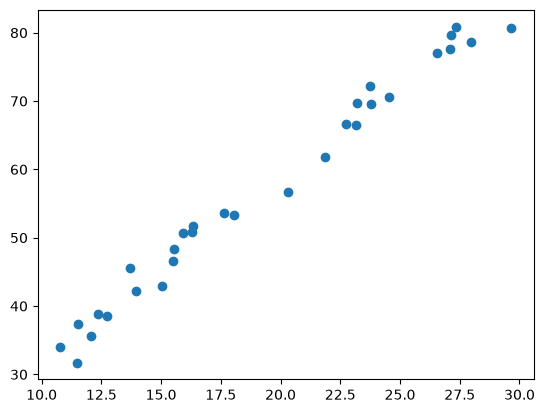

In [19]:
torch.manual_seed(123)  # fix random number generator for reproducibility

# Draw 30 random numbers from uniform a distribution on [0, 1)
# Multiplying by 20 stretches the range to [0, 20)
# Adding 10 shifts it to [10, 30)
x = 10 + 20 * torch.rand((30,)).to(dtype=torch.float)
# print(x)
x = x.reshape(
    -1, 1
)  # Turns flat vector of shape (30,) into column shape (30, 1); -1 means "infer dimension"
# print(x)
y = 2.7 * x + 2 * torch.randn_like(x) + 5  # Data Generation Process (DGP)
# True intercept = 5
# True slope = 2.7
# 2 * torch.randn_like(x) adds standard normal / Gaussian noise (mean 0, sd 1); actually, here sd = 2 due to "*2"

# Always: visualize data!
plt.scatter(x, y)

Linear regression implementation (NumPy):

array([[2.67754453],
       [5.42394903]])

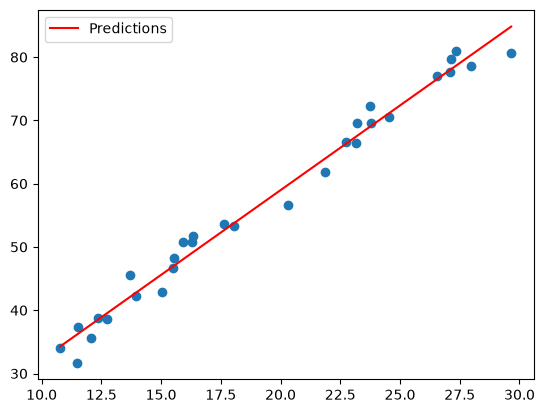

In [20]:
class LinearRegression:
    def __init__(self) -> None:
        self.w = None  # w[w0, w1] :: w[slope, intercept]

    def _add_constant(self, X: np.ndarray) -> np.ndarray:
        """Add a constant column to a matrix: (N, 1) -> (N, 2)


        [[x1, 1],
        [x2, 1],
        ...
        [xN, 1]]

        Intuition: later, prediction with w0 * x_i + w1 * 1 where w[w0, w1] :: w[slope, intercept]

        Args:
            X (np.ndarray): Original data matrix

        Returns:
            np.ndarray: Original data matrix with concatenated column of all ones.
        """
        return np.hstack((X, np.ones((len(X), 1))))

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        """Fit the parameters of the model to the data

        Args:
            X (np.ndarray): features
            y (np.ndarray): targets
        """
        X = self._add_constant(X)
        # minimize sum of squared errors: w = (x^T * x)^(-1) * x^T * y
        self.w = np.linalg.inv(X.T @ X) @ X.T @ y  # there is also np.linalg.pinv

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Use parameters to predict values

        Args:
            X (np.ndarray): features

        Returns:
            np.ndarray: predicted targets
        """
        X = self._add_constant(X)
        return X @ self.w


X = x.numpy()
model = LinearRegression()
model.fit(X, y.numpy())
preds = model.predict(X)

plt.scatter(x, y)

sort_idx = x.flatten().argsort()  # Sort x such that line is drawn left to right
plt.plot(x[sort_idx, 0], preds[sort_idx, 0], color="red", label="Predictions")
plt.legend()

model.w  # Observe: close to [2.7, 5]?

We could solve this here, but in general:
- Calculating the gradient manually is cumbersome
- Not all equation systems have analytical solutions

Hence, PyTorch helps us by
- computing gradients automatically
- and giving us the tools to optimize functions numerically.

### Automatic Differentiation

PyTorch keeps track of the so-called "computation graph" (We will come back to this in a few weeks).

This graph records every operation on (specific) tensors, thus traces the function that the tensors are used in.

Reminder: 
- Neural Networks (NNs) are basically just fancy functions. We use PyTorch to automatically get gradients/derivatives of functions.
- NNs manipulate an input by matrix-multiplications with weight matrices and additions with bias vectors; followed by nonlinear activation functions! (else, the network would collapse into a single linear map)
- As the NN manipulates the input, the computation graph is updated dynamically; PyTorch keeps track of this dynamic computation graph!

In [21]:
v = torch.ones(3)
print(v.requires_grad)

v = torch.ones(3, requires_grad=True)
print(v.requires_grad)


False
True


Let's define a simple function (i.e., our error measure!): $c (v) = \sum_i (v_i-2)^2$

In [22]:
v = torch.ones(3, requires_grad=True)
a = v - 2
b = a**2
c = b.sum()

print(v)
print(a)
print(b)
print(c)

tensor([1., 1., 1.], requires_grad=True)
tensor([-1., -1., -1.], grad_fn=<SubBackward0>)
tensor([1., 1., 1.], grad_fn=<PowBackward0>)
tensor(3., grad_fn=<SumBackward0>)


In [23]:
# from IPython.display import Image

# Image("comp-graph-example.png")

from IPython.display import HTML, display

print("a = v - 2")
print("b = a**2")
print("c = b.sum()")
display(
    HTML('<div style="text-align: center;"><img src="comp-graph-example.png"></div>')
)

a = v - 2
b = a**2
c = b.sum()


\begin{equation}
\frac{\partial c}{\partial v_i} = \frac{\partial c}{\partial b_i} \frac{\partial b_i}{\partial a_i} \frac{\partial a_i}{\partial v_i}
\end{equation}

\begin{equation}
\frac{\partial a_i}{\partial v_i} = 1, \frac{\partial b_i}{\partial a_i} = 2 * a_i, \frac{\partial c}{\partial b_i} = 1, \frac{\partial c}{\partial v_i} = 1 * (2 * a_i) * 1 = 2 * (v_i - 2)
\end{equation}

Note that $2 * (v_i - 2) = 2 * (1 - 2) = -2$ for $v_i = 1$. We can confirm this by performing backpropagation (on the computation graph) using `backward` on the last ouput (`c`)! Note the reverse direction -> backprop.

Calling `grad` reveals the gradients; $\frac{\partial c}{\partial v_i}, \text{with } v_i \in [1.0, 1.0, 1.0]$

We calculate the gradients $\nabla_v c = [\partial c/\partial v_1, \dots]^T$ by calling `.backward()` on `c`.

In [24]:
c.backward()

Now the `.grad` attribute is populated with the gradient values.

In [25]:
print(v)
print(v.grad)

tensor([1., 1., 1.], requires_grad=True)
tensor([-2., -2., -2.])


Not all tensor in the graph store gradients. Only "leafs", i.e., tensors that do not have further dependencies. Why?

The gradient of the loss w.r.t. the weights of the NN is what the optimizer needs. Intermediate computations have no further use once they are propagated back to the input...

In [26]:
print(a.grad)

None


/tmp/ipykernel_2307/638005153.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /__w/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:488.)
  print(a.grad)


### Numerical Optimization

How does having the gradient help us in any way?

_Gradient Descent_ (GD) is a method to optimize differentiable functions (details in the coming weeks).
All GD needs are the gradient values of the parameters, and access to the parameters itself. We have both with PyTorch.

$w^{(t + 1)} \leftarrow w^t - \alpha \cdot \nabla E(w^t)$, where $t + 1$ indicates the weight update (+ 1 time step) and $\alpha$ is the learning rate

### Define a model

In [27]:
# The part of torch with all neural network components (and loss functions)
# https://docs.pytorch.org/docs/2.14/nn.html#module-torch.nn
from torch import nn


class LinearRegressionPyTorch(nn.Module):
    def __init__(self, n_features):
        # Automatically registers parameters of layers inside it as trainable (i.e., requires_grad=True)
        super().__init__()
        self.linear = nn.Linear(n_features, 1, bias=True)  # x*A^T + b

    def forward(self, x):
        # Defines how the input is turned into an output; here: 1 weight + 1 bias => same as the NumPy model!
        return self.linear(x)


x = 10 + 20 * torch.rand((30,)).to(dtype=torch.float)
x = x.reshape(-1, 1)
y = 2.7 * x + 2 * torch.randn_like(x) + 5  # Data Generation Process (DGP)

model_pt = LinearRegressionPyTorch(x.size(-1))
for param_name, param in model_pt.named_parameters():
    print(param_name, param)

linear.weight Parameter containing:
tensor([[0.0740]], requires_grad=True)
linear.bias Parameter containing:
tensor([0.6886], requires_grad=True)


In [28]:
model_pt.linear.weight

Parameter containing:
tensor([[0.0740]], requires_grad=True)

In [29]:
model_pt.zero_grad()  # reset .grad (to None) so re-running gives the same result
preds = model_pt(x)  # This invokes foreward()!
print(preds)

tensor([[2.4724],
        [1.4457],
        [2.1248],
        [2.6910],
        [2.5123],
        [2.1960],
        [2.3145],
        [2.0989],
        [1.7620],
        [1.8893],
        [1.7182],
        [2.7838],
        [2.5763],
        [2.4278],
        [1.6014],
        [2.7401],
        [2.4010],
        [2.6810],
        [1.8778],
        [2.3259],
        [2.8917],
        [2.6668],
        [2.7626],
        [2.0135],
        [2.7329],
        [1.5892],
        [2.2330],
        [1.7522],
        [1.9963],
        [1.9794]], grad_fn=<AddmmBackward0>)


In [30]:
preds.sum().backward()  # backward pass! Here, we use the sum only because backwards needs a single value... not really a meaningful loss.
print(
    x.requires_grad
)  # False, because x is our data, not a parameter of the NN that gets optimized.

# Note that the weight remains unchanged. Backward only computes the gradients, it never updates the parameters!
print(model_pt.linear.weight)
print(model_pt.linear.weight.grad)

False
Parameter containing:
tensor([[0.0740]], requires_grad=True)
tensor([[629.5720]])


Whenever you use the model, the operations are recorded, so that the gradient can be computed later.
Some operations **should not be tracked**, e.g., evaluation on a validation data set.
Also, the recording is not free: it takes up memory.

### Evaluate a model

In [31]:
model_pt = LinearRegressionPyTorch(x.size(-1))

# the context manager temporarily turns off recording of operations
with torch.no_grad():
    out = model_pt(x)
    loss = out.sum()
    # loss.backward() # commented out (here), because the output has no grad_fn!
print(model_pt.linear.weight.grad)

out = model_pt(x)
loss = out.sum()
loss.backward()
print(model_pt.linear.weight.grad)


# You can use the function decorator for functions whose operations should not be tracked (e.g., evaluation)
@torch.no_grad()
def eval(model, x_val, y_val):
    pred = model(x_val)
    return (pred - y_val).sum()


None
tensor([[629.5720]])


A minimal training loop looks like this:

### Train a model

Additional tasks: 
- comment out "optimizer.zero_grad()" and run the cell below multiple times, then explain what u observe
- observe parameter changes based on learning rate changes

In [32]:
model_pt = LinearRegressionPyTorch(x.size(-1))

preds_epochs = []

optimizer = torch.optim.SGD(
    model_pt.parameters(), lr=5e-4
)  # register the parameters with the optimization method
loss_func = nn.MSELoss()
n_epochs = 20
for epoch in range(n_epochs):
    output = model_pt(x)  # Step 1: Forward pass
    loss = loss_func(output, y)  # Step 2: Compute loss, here: MSE
    optimizer.zero_grad()  # Step 3 : rest gradients, i.e., set .grad attribute to None
    # PyTorch accumulates (sums) the gradients on subsequent backward passes, thus we set the gradients to zero before we perform backpropagation.
    # Why accumulate? Well, in some cases we want this behavior: e.g., RNNs, compute gradient over loss summed over multiple mini-batches ...
    loss.backward()  # Step 4: Compute gradients (populate .grad attributes again)
    optimizer.step()  # Step 5: Optimization step (update parameters)

    print(f"{epoch=}: loss={loss.item()}")
    preds_epochs.append(output.detach())

print(*model_pt.parameters())

epoch=0: loss=5910.3193359375
epoch=1: loss=1652.3736572265625
epoch=2: loss=465.6243896484375
epoch=3: loss=134.8601837158203
epoch=4: loss=42.671321868896484
epoch=5: loss=16.976774215698242
epoch=6: loss=9.81511116027832
epoch=7: loss=7.818855285644531
epoch=8: loss=7.262251853942871
epoch=9: loss=7.106907844543457
epoch=10: loss=7.063401699066162
epoch=11: loss=7.0510687828063965
epoch=12: loss=7.0474042892456055
epoch=13: loss=7.046181678771973
epoch=14: loss=7.045633792877197
epoch=15: loss=7.045263767242432
epoch=16: loss=7.044958591461182
epoch=17: loss=7.044651508331299
epoch=18: loss=7.044351100921631
epoch=19: loss=7.044068813323975
Parameter containing:
tensor([[2.9045]], requires_grad=True) Parameter containing:
tensor([0.2494], requires_grad=True)


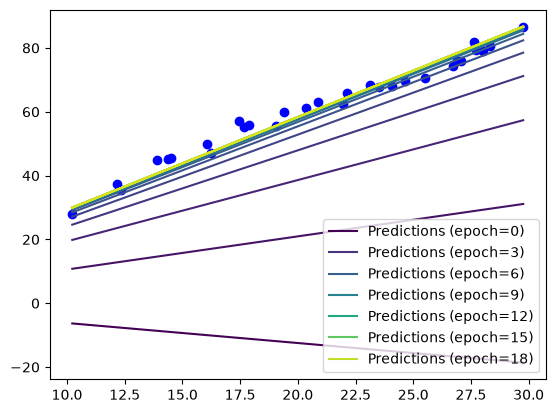

In [33]:
import matplotlib as mpl

fig, ax = plt.subplots()
cmap = mpl.colormaps.get_cmap("viridis")
label_every_n_epoch = 3
ax.scatter(x.view(-1), y.view(-1), color="blue")
for epoch, preds in enumerate(preds_epochs):
    sort_idx = x.flatten().argsort()
    if epoch % label_every_n_epoch == 0:
        kwargs = {
            "color": cmap(epoch / len(preds_epochs)),
            "label": f"Predictions ({epoch=})",
        }
    else:
        kwargs = {"color": cmap(epoch / len(preds_epochs))}

    ax.plot(
        x[sort_idx, 0],
        preds[sort_idx, 0],
        **kwargs,
    )
ax.legend()


There is more, which we will cover in the upcoming weeks.